# 2. Проверка эксперимента

Проверяю, что деление на treatment и control честное, что история покупок закончилась до коммуникации,
и оцениваю средний эффект коммуникации на долю покупателей. Агрегаты - SQL-запросы из `sql/experiment.sql`,
статистика - `src/stats.py`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, db, plots, stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plots.setup()
con = db.connect()
T, C = plots.GROUP_COLORS["treatment"], plots.GROUP_COLORS["control"]

## SRM

Хи-квадрат против ожидаемого деления 50/50. В описании датасета доля treatment - 0,5, само ожидаемое деление -
допущение. Проверяю на всех 200 039 клиентах и в каждой части разбиения.

In [2]:
groups = db.run(con, "experiment.sql", "group_sizes")
groups[["chi2", "p_value"]] = [stats.srm(t, c) for t, c in zip(groups.n_treatment, groups.n_control)]
groups["treatment_share"] = groups.n_treatment / (groups.n_treatment + groups.n_control)
groups.round(4)

,part,n_treatment,n_control,chi2,p_value,treatment_share
0,all,99981,100058,0.0296,0.8633,0.4998
1,train,59989,60034,0.0169,0.8967,0.4998
2,valid,19996,20012,0.0064,0.9362,0.4998
3,test,19996,20012,0.0064,0.9362,0.4998


На всех клиентах 99 981 в treatment и 100 058 в control, доля 0,4998, p = 0,86: признаков SRM нет. В частях разбиения
p от 0,90 до 0,94, но это почти не проверка: разбиение стратифицировано по treatment x target, и доля treatment в
каждой части совпадает с общей по построению.

## Баланс групп

Признаки из `clients` (даты сдвинуты на 3 часа, этап 1) и простые агрегаты истории до `CUTOFF` включительно.
Возраст вне 14-100 - NULL, отдельно доля таких NULL. Давность карты и последней покупки - в днях до `CUTOFF`.
SMD - разница средних, делённая на корень из средней дисперсии двух групп. Порог |SMD| < 0,1.

In [3]:
db.create_view(con, "experiment.sql", "covariates")
moments = db.run(con, "experiment.sql", "covariate_moments")
moments["smd"] = stats.smd(moments.mean_treatment, moments.mean_control, moments.var_treatment, moments.var_control)
LABELS = {
    "age": "возраст, лет",
    "age_null": "возраст вне 14-100 (NULL)",
    "gender_f": "пол F",
    "gender_m": "пол M",
    "gender_u": "пол U (не указан)",
    "card_age_days": "давность карты, дней",
    "redeemed_before_cutoff": "списывал баллы до CUTOFF",
    "n_transactions": "чеков до CUTOFF",
    "purchase_sum": "сумма покупок до CUTOFF, руб.",
    "days_since_last": "дней с последней покупки",
}
moments["label"] = moments.covariate.map(LABELS)
moments = moments.set_index("covariate").loc[list(LABELS)].reset_index()
moments[["covariate", "mean_treatment", "mean_control", "smd", "n_treatment", "n_control"]].round(4)

,covariate,mean_treatment,mean_control,smd,n_treatment,n_control
0,age,46.4645,46.3781,0.0054,99530,99626
1,age_null,0.0045,0.0043,0.0029,99981,100058
2,gender_f,0.3692,0.3676,0.0032,99981,100058
3,gender_m,0.1673,0.1678,-0.0013,99981,100058
4,gender_u,0.4635,0.4646,-0.0021,99981,100058
5,card_age_days,434.1018,432.3607,0.0085,99981,100058
6,redeemed_before_cutoff,0.8007,0.7979,0.0069,99981,100058
7,n_transactions,20.1856,20.0561,0.0073,99981,100058
8,purchase_sum,8625.6995,8569.3661,0.0063,99981,100058
9,days_since_last,5.8283,5.8294,-0.0002,99981,100058


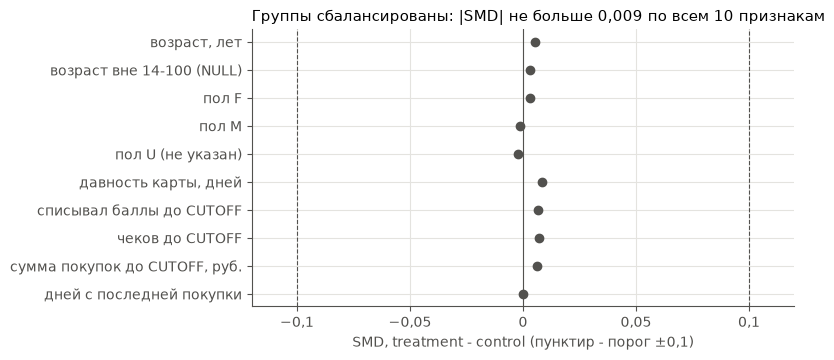

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(moments))[::-1]
ax.scatter(moments.smd, y, color=plots.INK, zorder=3)
ax.axvline(0, color=plots.INK, lw=0.8)
for x in (-0.1, 0.1):
    ax.axvline(x, color=plots.INK, lw=0.8, ls="--")
ax.set_yticks(y, moments.label)
ax.set_xlim(-0.12, 0.12)
plots.decimal_comma(ax.xaxis)
ax.set_xlabel("SMD, treatment - control (пунктир - порог ±0,1)")
ax.set_title(f"Группы сбалансированы: |SMD| не больше {moments.smd.abs().max():.3f} по всем 10 признакам".replace(".", ","))
plots.save(fig, "balance_smd.png")
plt.show()

Все |SMD| меньше 0,01, на порядок ниже порога. Самое большое - у давности карты, 0,0085. У возраста 883 NULL,
SMD по нему считается по остальным клиентам.

## Конец истории покупок

По описанию датасета purchases - история до коммуникации, но даты коммуникации нет. Проверяю, нет ли расхождений
между группами в конце истории: если бы коммуникация пришлась на последние дни, treatment начал бы покупать иначе
ещё в purchases. По каждому дню с 2019-02-26 по 2019-03-18 считаю долю купивших клиентов и среднее число чеков
на клиента в каждой группе, разницу treatment - control, её 95%-интервал (нормальное приближение) и MDE при
alpha = 0,05 и мощности 80%: MDE = (1,96 + 0,84) x SE, примерно 2,8 SE. Знаменатель - все клиенты группы.

In [5]:
daily = db.run(con, "experiment.sql", "daily_by_group")
t = daily[daily.treatment_flg == 1].set_index("day")
c = daily[daily.treatment_flg == 0].set_index("day")
share_t, share_t_lo, share_t_hi = stats.prop_ci(t.n_buyers, t.n_clients)
share_c, share_c_lo, share_c_hi = stats.prop_ci(c.n_buyers, c.n_clients)
d, lo, hi = stats.diff_props_ci(t.n_buyers, t.n_clients, c.n_buyers, c.n_clients)
dm, mlo, mhi = stats.diff_means_ci(t.trn_per_client, t.trn_var, t.n_clients, c.trn_per_client, c.trn_var, c.n_clients)
by_day = pd.DataFrame({
    "share_treatment": share_t, "share_control": share_c,
    "diff_pp": d * 100, "diff_lo_pp": lo * 100, "diff_hi_pp": hi * 100,
    "mde_pp": stats.mde(stats.diff_props_se(t.n_buyers, t.n_clients, c.n_buyers, c.n_clients)) * 100,
    "trn_treatment": t.trn_per_client, "trn_control": c.trn_per_client,
    "trn_diff": dm, "trn_diff_lo": mlo, "trn_diff_hi": mhi,
})
by_day.round(4)

,share_treatment,share_control,diff_pp,diff_lo_pp,diff_hi_pp,mde_pp,trn_treatment,trn_control,trn_diff,trn_diff_lo,trn_diff_hi
day,,,,,,,,,,,
2019-02-26,0.1785,0.1756,0.2926,-0.0420,0.6271,0.4782,0.2000,0.1960,0.0040,0.0000,0.0081
2019-02-27,0.1971,0.1955,0.1661,-0.1820,0.5142,0.4976,0.2238,0.2226,0.0011,-0.0033,0.0055
2019-02-28,0.1885,0.1893,-0.0784,-0.4215,0.2647,0.4904,0.2126,0.2140,-0.0014,-0.0056,0.0028
2019-03-01,0.1972,0.1951,0.2161,-0.1320,0.5641,0.4975,0.2252,0.2224,0.0028,-0.0015,0.0071
2019-03-02,0.1881,0.1851,0.3043,-0.0371,0.6458,0.4881,0.2166,0.2124,0.0042,-0.0001,0.0086
2019-03-03,0.1702,0.1697,0.0471,-0.2821,0.3762,0.4705,0.1952,0.1938,0.0014,-0.0028,0.0055
2019-03-04,0.1910,0.1923,-0.1292,-0.4742,0.2158,0.4931,0.2158,0.2180,-0.0022,-0.0064,0.0020
2019-03-05,0.1900,0.1879,0.2135,-0.1296,0.5566,0.4904,0.2156,0.2144,0.0013,-0.0030,0.0055
2019-03-06,0.1885,0.1891,-0.0594,-0.4025,0.2836,0.4903,0.2156,0.2156,-0.0000,-0.0043,0.0043


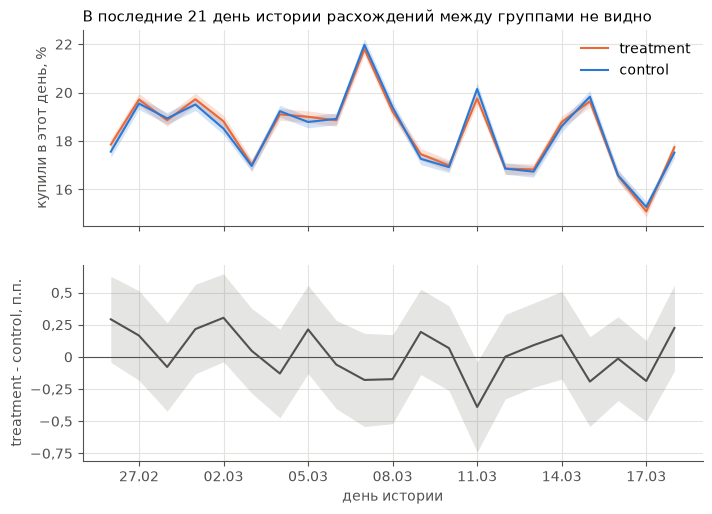

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
days = by_day.index
ax1.plot(days, share_t * 100, color=T, lw=1.5, label="treatment")
ax1.fill_between(days, share_t_lo * 100, share_t_hi * 100, color=T, alpha=0.2, lw=0)
ax1.plot(days, share_c * 100, color=C, lw=1.5, label="control")
ax1.fill_between(days, share_c_lo * 100, share_c_hi * 100, color=C, alpha=0.2, lw=0)
ax1.set_ylabel("купили в этот день, %")
ax1.legend(loc="upper right")
plots.decimal_comma(ax1.yaxis)
ax2.plot(days, d * 100, color=plots.INK, lw=1.5)
ax2.fill_between(days, lo * 100, hi * 100, color=plots.INK, alpha=0.15, lw=0)
ax2.axhline(0, color=plots.INK, lw=0.8)
ax2.set_ylabel("treatment - control, п.п.")
ax2.set_xlabel("день истории")
plots.decimal_comma(ax2.yaxis)
ax2.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
ax1.set_title("В последние 21 день истории расхождений между группами не видно")
plots.save(fig, "daily_last21.png")
plt.show()

In [7]:
outside = by_day[(by_day.diff_lo_pp > 0) | (by_day.diff_hi_pp < 0)]
outside_trn = by_day[(by_day.trn_diff_lo > 0) | (by_day.trn_diff_hi < 0)]
print("дней, где интервал разницы долей не накрывает 0:", len(outside), list(outside.index.astype(str)))
print("дней, где интервал разницы числа чеков не накрывает 0:", len(outside_trn), list(outside_trn.index.astype(str)))
print("последние 7 дней, разница долей, п.п.:", by_day.diff_pp.tail(7).round(2).tolist())
print(f"MDE одного дня, п.п.: от {by_day.mde_pp.min():.2f} до {by_day.mde_pp.max():.2f}")

дней, где интервал разницы долей не накрывает 0: 1 ['2019-03-11']
дней, где интервал разницы числа чеков не накрывает 0: 1 ['2019-02-26']
последние 7 дней, разница долей, п.п.: [0.0, 0.09, 0.17, -0.19, -0.01, -0.19, 0.22]
MDE одного дня, п.п.: от 0.45 до 0.52


Интервал разницы долей не накрывает 0 только в одном дне из 21 (2019-03-11, -0,39 п.п.), а при уровне 5%
случайно ожидается около одного. По числу чеков на клиента - тоже в одном дне (2019-02-26, нижняя граница на нуле).
В последние 7 дней разница долей от -0,19 до +0,22 п.п. без тренда. MDE одного дня - от 0,45 до 0,52 п.п.: разницу
в доле купивших меньше примерно 0,5 п.п. за день эта проверка бы скорее всего не увидела.

Дни не независимы: это одни и те же клиенты, поэтому общий тест по 21 дню не делаю. Вместо него - проверка на уровне
клиента, где клиенты независимы: покупал ли клиент в последние 3 дня и в последние 7 дней истории. По одному тесту
на окно.

In [8]:
recent = db.run(con, "experiment.sql", "recent_buyers").set_index("treatment_flg")
rows = []
for w in ["3d", "7d"]:
    k = recent[f"n_bought_{w}"]
    d, lo, hi = stats.diff_props_ci(k[1], recent.n_clients[1], k[0], recent.n_clients[0])
    se = stats.diff_props_se(k[1], recent.n_clients[1], k[0], recent.n_clients[0])
    rows.append({
        "окно": w,
        "доля treatment": k[1] / recent.n_clients[1],
        "доля control": k[0] / recent.n_clients[0],
        "разница, п.п.": d * 100,
        "95%, п.п.": f"{lo * 100:.2f} ... {hi * 100:.2f}",
        "MDE, п.п.": stats.mde(se) * 100,
    })
pd.DataFrame(rows).round(4)

,окно,доля treatment,доля control,"разница, п.п.","95%, п.п.","MDE, п.п."
0,3d,0.3803,0.3802,0.0123,-0.41 ... 0.44,0.6082
1,7d,0.6239,0.6215,0.2359,-0.19 ... 0.66,0.6072


Покупали в последние 3 дня 38,03% treatment и 38,02% control: разница +0,01 п.п. (от -0,41 до +0,44), MDE 0,61 п.п.
В последние 7 дней - 62,39% и 62,15%: +0,24 п.п. (от -0,19 до +0,66), MDE 0,61 п.п.

Расхождений между группами в конце истории не обнаружено (MDE 0,61 п.п. на уровне клиента за 3 и 7 дней, около
0,5 п.п. за один день). Это в 5 раз меньше среднего эффекта на target (+3,3 п.п., ниже). По описанию датасета purchases -
история до коммуникации. `CUTOFF` оставляю 2019-03-18.

## Разведочно: первое списание баллов после CUTOFF

`first_redeem_date` после `CUTOFF` - событие уже после коммуникации, в признаки не идёт. Смотрю на него разведочно:
различается ли оно между группами.

In [9]:
redeem = db.run(con, "experiment.sql", "redeem_after_cutoff").set_index("treatment_flg")
share, s_lo, s_hi = stats.prop_ci(redeem.n_redeem_after, redeem.n_clients)
redeem["share"], redeem["lo"], redeem["hi"] = share, s_lo, s_hi
d, lo, hi = stats.diff_props_ci(redeem.n_redeem_after[1], redeem.n_clients[1], redeem.n_redeem_after[0], redeem.n_clients[0])
print(f"разница treatment - control: {d * 100:+.2f} п.п., 95% от {lo * 100:+.2f} до {hi * 100:+.2f}")
redeem.round(4)

разница treatment - control: +0.39 п.п., 95% от +0.11 до +0.67


,n_clients,n_redeem_after,share,lo,hi
treatment_flg,,,,,
0,100058,11110,0.1110,0.1091,0.1130
1,99981,11490,0.1149,0.1129,0.1169


Впервые списали баллы после `CUTOFF` 11,49% клиентов treatment и 11,10% control: разница +0,39 п.п.
(от +0,11 до +0,67). Это разведочная находка, гипотеза не была задана заранее: возможно, коммуникация подталкивает
к первому списанию. Для анализа из неё следует одно: дата после `CUTOFF` может зависеть от treatment, поэтому
в признаках её нет ни в каком виде.

## Средний эффект

Разница долей покупателей treatment - control на всех 200 039 клиентах. Интервал - нормальное приближение
и бутстреп рядом: 1 000 повторов, клиентов пересэмплирую отдельно внутри treatment и control, перцентильный интервал.

Это описательная оценка эксперимента. Модели здесь не выбираются, и разбиение на train/valid/test она не использует,
поэтому test для оценки моделей остаётся нетронутым: на нём не подбирается ни одно решение.

In [10]:
y = db.run(con, "experiment.sql", "target_arrays")
y_t = y.target[y.treatment_flg == 1].to_numpy()
y_c = y.target[y.treatment_flg == 0].to_numpy()
ate, n_lo, n_hi = stats.diff_props_ci(y_t.sum(), y_t.size, y_c.sum(), y_c.size)
_, b_lo, b_hi = stats.bootstrap_diff(y_t, y_c, n_boot=1000, seed=config.SEED)
effect = pd.DataFrame({
    "доля покупателей treatment": [y_t.mean()],
    "доля покупателей control": [y_c.mean()],
    "разница, п.п.": [ate * 100],
    "нормальное, п.п.": [f"{n_lo * 100:.2f} ... {n_hi * 100:.2f}"],
    "бутстреп, п.п.": [f"{b_lo * 100:.2f} ... {b_hi * 100:.2f}"],
    "относительно control, %": [ate / y_c.mean() * 100],
})
effect.round(4)

,доля покупателей treatment,доля покупателей control,"разница, п.п.","нормальное, п.п.","бутстреп, п.п.","относительно control, %"
0,0.6365,0.6033,3.3231,2.90 ... 3.75,2.91 ... 3.74,5.5084


In [11]:
per_1000 = pd.DataFrame({
    "доп. покупателей на 1 000 сообщений": [ate * 1000],
    "нормальное": [f"{n_lo * 1000:.1f} ... {n_hi * 1000:.1f}"],
    "бутстреп": [f"{b_lo * 1000:.1f} ... {b_hi * 1000:.1f}"],
})
per_1000.round(1)

,доп. покупателей на 1 000 сообщений,нормальное,бутстреп
0,33.2,29.0 ... 37.5,29.1 ... 37.4


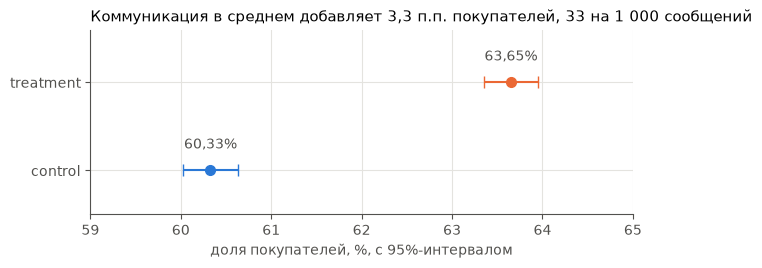

In [12]:
fig, ax = plt.subplots(figsize=(7, 2.4))
for i, (name, arr, color) in enumerate([("control", y_c, C), ("treatment", y_t, T)]):
    p, plo, phi = stats.prop_ci(arr.sum(), arr.size)
    ax.errorbar(p * 100, i, xerr=[[(p - plo) * 100], [(phi - p) * 100]], fmt="o", color=color, capsize=4, ms=7)
    ax.text(p * 100, i + 0.25, f"{p * 100:.2f}%".replace(".", ","), ha="center", color=plots.INK)
ax.set_yticks([0, 1], ["control", "treatment"])
ax.set_ylim(-0.5, 1.6)
ax.set_xlim(59, 65)
plots.decimal_comma(ax.xaxis)
ax.set_xlabel("доля покупателей, %, с 95%-интервалом")
ate_pp = f"{ate * 100:.1f}".replace(".", ",")
ax.set_title(f"Коммуникация в среднем добавляет {ate_pp} п.п. покупателей, {ate * 1000:.0f} на 1 000 сообщений")
plots.save(fig, "ate.png")
plt.show()

Купили 63,65% клиентов treatment и 60,33% control. Разница +3,32 п.п.: нормальный интервал от 2,90 до 3,75,
бутстреп от 2,91 до 3,74, почти то же. Относительно control это +5,5%. При рассылке всем это 33,2 дополнительных
покупателя на 1 000 сообщений (от 29,0 до 37,5). Это ответ на вопрос «работает ли коммуникация в среднем».
Бейзлайн «рассылка всем» для сравнения моделей считаю отдельно на test, на тех же клиентах, что и модели
(`docs/plan.md`).

## Итоги

- SRM нет: 99 981 против 100 058, p = 0,86.
- Группы сбалансированы: |SMD| < 0,01 по всем 10 признакам при пороге 0,1.
- Расхождений между группами в конце истории не обнаружено: MDE 0,61 п.п. на уровне клиента за 3 и 7 дней.
  `CUTOFF` = 2019-03-18 не сдвигаю.
- Разведочно: первое списание баллов после `CUTOFF` в treatment чаще на 0,39 п.п. В признаках этой даты нет.
- Коммуникация в среднем работает: +3,32 п.п. покупателей (от 2,90 до 3,75), 33 дополнительных покупателя
  на 1 000 сообщений при рассылке всем.